# Baseline SVM Linear dengan Feature Engineering

Eksperimen `svm_baseline_linear` — Akram, Kelompok 17 DerbyCounty.
Implementasi SVM from scratch dibandingkan dengan scikit-learn pada seluruh
data train yang sudah dibersihkan, menggunakan fold dan preprocessing yang sama.

Optimasi dual memakai `scipy.optimize.minimize(method="SLSQP")` pada blok
maksimal 64 alpha dengan batas `0 <= alpha <= C` dan kendala `sum(alpha * y) = 0`.
Blok kecil menghindari penyimpanan matriks kernel seluruh data. Kalibrasi sigmoid
memakai solver BFGS dari SciPy; kernel, support vector, dan prediksi dihitung sendiri.
`DEVICE='auto'` memakai CUDA untuk perhitungan blok kernel jika tersedia,
lalu CPU sebagai fallback. Gunakan `'cuda'` untuk mewajibkan kernel GPU
atau `'cpu'` untuk seluruh perhitungan di CPU. Solver SciPy berjalan di CPU.
Output dan skor yang tersimpan berasal dari solver SMO CPU sebelumnya;
evaluasi dengan solver SciPy perlu menjalankan ulang notebook.

Referensi solver: [SciPy SLSQP](https://docs.scipy.org/doc/scipy/reference/optimize.minimize-slsqp.html)
dan [SciPy BFGS](https://docs.scipy.org/doc/scipy/reference/optimize.minimize-bfgs.html).


## Ringkasan hasil

- OOF Macro F1 from scratch **0,7656**, std fold **0,0050**, threshold **0,45**.
  Pembanding scikit-learn **0,7659** dengan threshold **0,44**; selisih skor -0,00029.
- Kelima model from scratch dan model akhir konvergen, tanpa peringatan optimasi
  termasuk saat kalibrasi. CV from scratch selesai dalam 307,5 detik.
- Baseline ini masih di bawah Decision Tree **0,8291** pada log tim, sehingga belum
  memenuhi syarat peningkatan OOF untuk submission Kaggle.
- Model tersimpan dan CSV lokal berisi **6.844** prediksi: **4.836** tidak batal dan
  **2.008** batal. Prediksi identik setelah save/load; CSV lolos pemeriksaan ID dan readback.


## Metode dan batas eksperimen

- Sumber: `data/train.csv`, `data/test.csv`, dan `data/sample_submission.csv`.
  Cleaning memakai `clean_train`; test tidak dibuang barisnya.
- Stratified 5-fold dengan seed 42. `SVMPreprocessor` di-fit
  hanya pada train setiap fold: imputasi, indikator missing, one-hot,
  standardisasi, dan tujuh fitur turunan dari pipeline tim.
- Baseline: kernel linear, `C=0.01`, `tol=0.01`, `max_iter=1000`.
  C dan toleransi dipilih untuk baseline yang terjangkau secara komputasi;
  belum ada pencarian hyperparameter berdasarkan skor.
- Probabilitas from scratch memakai sigmoid dari holdout internal 20% train.
  `SVC(probability=True)` memakai kalibrasi internal scikit-learn; metode
  kalibrasinya berbeda sehingga probabilitas tidak harus identik.
- Threshold dicari terpisah untuk setiap model pada OOF dengan helper tim.
  Skor setelah pemilihan threshold adalah hasil pengembangan, bukan estimasi
  dari test independen. Std menunjukkan variasi antar-fold, bukan confidence interval.
- Model akhir tetap SVM tunggal from scratch. File submission hanya dibuat
  lokal; pengiriman Kaggle mengikuti pemegang pipeline.

## Alasan pemilihan hyperparameter

- Kernel `linear` dipakai sebagai titik awal dengan batas keputusan linear pada
  fitur hasil preprocessing. Model ini menjadi acuan sebelum menambah interaksi
  non-linear melalui kernel lain.
- `C=0.01` memberi regularisasi lebih kuat daripada C yang lebih besar: model
  lebih mengutamakan margin lebar dan mengizinkan lebih banyak pelanggaran margin.
  Nilai kecil ini dipakai sebagai konfigurasi awal yang sederhana, belum sebagai
  hasil pencarian C terbaik. Biaya training tetap diperiksa dari hasil run.

- `tol=0.01` memberi toleransi pelanggaran kondisi KKT sebesar 0,01 agar optimasi
  tidak mengejar ketelitian yang terlalu mahal untuk eksperimen awal.
  `max_iter=1000` membatasi jumlah putaran jika toleransi belum tercapai;
  tiap putaran memuat maksimal `ceil(n_train / 64)` pembaruan blok QP.
  nilai ini bukan target jumlah iterasi. Kelima model utama pada konfigurasi
  yang dilaporkan mencapai toleransi tersebut.
- `seed=42` membuat pembagian data dan holdout kalibrasi dapat direproduksi;
  seed tidak dipilih dengan membandingkan skor.

- Threshold `0.45` diperoleh dari pencarian Macro F1 tertinggi pada prediksi OOF
  dalam rentang 0,20 sampai 0,80 dengan langkah 0,01, bukan ditentukan dari test.
  Karena threshold juga dinilai pada OOF yang sama, skor ini adalah hasil pengembangan.


## Setup

Jalankan dengan environment berisi `requirements.txt`, Jupyter/ipykernel,
dan nbconvert. Root repo ditemukan otomatis, termasuk saat cwd di folder notebook.

In [1]:
import hashlib
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.metrics import f1_score
from sklearn.svm import SVC
from threadpoolctl import threadpool_limits

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'src' / 'models').is_dir())
sys.path.insert(0, str(ROOT / 'src'))

from models import SVM
from preprocessing import SVMPreprocessor, TARGET, clean_train
from utils import (best_threshold, confusion_matrix, cross_val_proba,
                   f1_per_class, fold_scores, load_model, macro_f1,
                   save_model, stratified_kfold)

SEED = 42
DEVICE = 'auto'
N_FOLDS = 5
EXP_NAME = 'svm_baseline_linear'
SVM_PARAMS = dict(kernel='linear', C=0.01, tol=0.01, max_iter=1000, seed=SEED, device=DEVICE)
MODEL_PATH = ROOT / 'output' / 'models' / f'{EXP_NAME}.pkl'
SUB_PATH = ROOT / 'output' / 'submissions' / f'submission_{EXP_NAME}.csv'
FIG_PATH = ROOT / 'output' / 'figures' / f'{EXP_NAME}.png'
plt.rcParams.update({'font.size': 11, 'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False})

print('Python', sys.version.split()[0], '| NumPy', np.__version__,
      '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__)
print(SVM_PARAMS)

Python 3.12.6 | NumPy 2.2.6 | pandas 2.3.0 | scikit-learn 1.9.0
{'kernel': 'linear', 'C': 0.01, 'tol': 0.01, 'max_iter': 1000, 'seed': 42}


## Data dan fold

ID dibaca sebagai string agar ID numerik maupun yang menyerupai notasi ilmiah
tidak berubah. Hash mencatat input persis yang dipakai untuk eksperimen.

In [2]:
train_raw = pd.read_csv(ROOT / 'data' / 'train.csv', dtype={'id': str})
test_raw = pd.read_csv(ROOT / 'data' / 'test.csv', dtype={'id': str})
sample = pd.read_csv(ROOT / 'data' / 'sample_submission.csv', dtype={'id': str})
train = clean_train(train_raw)
y = train[TARGET].to_numpy()
assert set(np.unique(y)) == {0, 1}
assert test_raw['id'].is_unique and sample['id'].is_unique
assert test_raw['id'].equals(sample['id'])

print('Train mentah:', train_raw.shape, '| Train bersih:', train.shape,
      '| Test:', test_raw.shape)
print('Duplikat dibuang:', len(train_raw) - len(train))
display(train[TARGET].value_counts().sort_index().rename('jumlah').to_frame())
for filename in ['train.csv', 'test.csv', 'sample_submission.csv']:
    digest = hashlib.sha256((ROOT / 'data' / filename).read_bytes()).hexdigest()
    print(f'{filename}: sha256={digest}')

folds = stratified_kfold(y, n_splits=N_FOLDS, seed=SEED)
validation_indices = np.concatenate([va for _, va in folds])
assert np.array_equal(np.sort(validation_indices), np.arange(len(y)))
assert all(not np.intersect1d(tr, va).size and len(tr) + len(va) == len(y)
           for tr, va in folds)
display(pd.DataFrame([
    {'fold': k, 'train': len(tr), 'validasi': len(va), 'rasio_batal': y[va].mean()}
    for k, (tr, va) in enumerate(folds, 1)
]).round(4))

Train mentah: (27373, 19) | Train bersih: (27309, 19) | Test: (6844, 18)
Duplikat dibuang: 64


,jumlah
is_canceled,
0,18365
1,8944


train.csv: sha256=2773be159fee45aac59b32354949d00af0badbc37c45420d5ab5dc676bbcc7ed
test.csv: sha256=aa59d8ddeb73efea1887eb8c7611d848dff332bc4ade7258c3408cec07050610
sample_submission.csv: sha256=be2885697720fa1c645a422510a9ca2e81f6e14cb54b6dfd8760d5c3960e1c1b


,fold,train,validasi,rasio_batal
0,1,21847,5462,0.3275
1,2,21847,5462,0.3275
2,3,21847,5462,0.3275
3,4,21847,5462,0.3275
4,5,21848,5461,0.3274


## SVM from scratch: probabilitas OOF

Training memakai satu thread BLAS agar operasi matriks kecil tidak terkena
overhead banyak thread. Seluruh baris train tetap digunakan, tanpa subsampling.
Peringatan optimasi dicatat termasuk model sementara untuk kalibrasi.

In [3]:
scratch_models = []

def make_scratch():
    print(f'Mulai fold {len(scratch_models) + 1}/{N_FOLDS}', flush=True)
    model = SVM(**SVM_PARAMS)
    scratch_models.append(model)
    return model

started = time.perf_counter()
with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as cv_warnings:
    warnings.simplefilter('always', RuntimeWarning)
    oof_scratch = cross_val_proba(make_scratch, SVMPreprocessor, train, y, folds)
scratch_seconds = time.perf_counter() - started
assert oof_scratch.shape == y.shape
assert np.isfinite(oof_scratch).all() and ((0 <= oof_scratch) & (oof_scratch <= 1)).all()

diagnostics = pd.DataFrame([
    {'fold': k, 'iterations': model.n_iter_, 'converged': model.converged_,
     'support_vectors': len(model.support_), 'device': model.device_}
    for k, model in enumerate(scratch_models, 1)
])
display(diagnostics)
print(f'Waktu CV from scratch: {scratch_seconds:.1f} detik')
print('Jumlah peringatan CV (termasuk kalibrasi):', len(cv_warnings))
for message in sorted({str(w.message) for w in cv_warnings}):
    print(message)

Mulai fold 1/5


Mulai fold 2/5


Mulai fold 3/5


Mulai fold 4/5


Mulai fold 5/5


,fold,iterations,converged,support_vectors
0,1,45,True,10627
1,2,36,True,10634
2,3,50,True,10678
3,4,35,True,10603
4,5,40,True,10596


Waktu CV from scratch: 307.5 detik
Jumlah peringatan CV (termasuk kalibrasi): 0


## Perbandingan scikit-learn

`SVC` menerima C, kernel, dan toleransi yang sama, dengan seed 42 dan tanpa
class weighting. `max_iter=-1` membiarkan solver scikit-learn mencapai toleransi;
jumlah iterasinya tidak setara dengan satu putaran blok QP pada implementasi ini.
Adapter mengubah keluaran probabilitas menjadi vektor P(kelas 1) untuk helper evaluasi.

In [4]:
class SklearnWrapper:
    def __init__(self, model):
        self.model = model

    def fit(self, X, y):
        self.model.fit(X, y)
        return self

    def predict_proba(self, X):
        return self.model.predict_proba(X)[:, 1]

started = time.perf_counter()
with threadpool_limits(limits=1):
    # shortcut: probability=True deprecated di sklearn 1.9, migrasi ke CalibratedClassifierCV sebelum 1.11.
    oof_sklearn = cross_val_proba(
        lambda: SklearnWrapper(SVC(kernel='linear', C=SVM_PARAMS['C'],
                                  tol=SVM_PARAMS['tol'], probability=True,
                                  random_state=SEED)),
        SVMPreprocessor, train, y, folds)
sklearn_seconds = time.perf_counter() - started
assert oof_sklearn.shape == y.shape
assert np.isfinite(oof_sklearn).all() and ((0 <= oof_sklearn) & (oof_sklearn <= 1)).all()
print(f'Waktu CV scikit-learn: {sklearn_seconds:.1f} detik')

C:\Users\Akram\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\Akram\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\Akram\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\Akram\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\Akram\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Waktu CV scikit-learn: 561.0 detik


## Hasil dan pemeriksaan metrik

Macro F1 dari helper tim dicek terhadap `sklearn.metrics.f1_score`.
Setiap fold menggunakan satu threshold global yang dipilih dari gabungan OOF.

In [5]:
def report(name, proba, seconds):
    threshold, score = best_threshold(y, proba)
    scores = fold_scores(y, proba, folds, threshold)
    predictions = (proba >= threshold).astype(int)
    assert np.isclose(score, f1_score(y, predictions, average='macro'))
    return dict(model=name, threshold=threshold, oof_macro_f1=score,
                fold_mean=float(scores.mean()), fold_std=float(scores.std()),
                cv_seconds=seconds)

res_scratch = report('SVM from scratch', oof_scratch, scratch_seconds)
res_sklearn = report('sklearn SVC', oof_sklearn, sklearn_seconds)
comparison = pd.DataFrame([res_scratch, res_sklearn]).set_index('model')
display(comparison.round(4))
per_fold = pd.DataFrame({
    'fold': np.arange(1, N_FOLDS + 1),
    'from_scratch': fold_scores(y, oof_scratch, folds, res_scratch['threshold']),
    'sklearn': fold_scores(y, oof_sklearn, folds, res_sklearn['threshold']),
})
display(per_fold.round(4))
pred_oof = (oof_scratch >= res_scratch['threshold']).astype(int)
print('Confusion matrix [[TN, FP], [FN, TP]]:')
print(confusion_matrix(y, pred_oof))
print('F1 kelas 0 dan 1:', f1_per_class(y, pred_oof).round(4))
print('Selisih OOF from scratch - sklearn:',
      round(res_scratch['oof_macro_f1'] - res_sklearn['oof_macro_f1'], 6))

,threshold,oof_macro_f1,fold_mean,fold_std,cv_seconds
model,,,,,
SVM from scratch,0.45,0.7656,0.7656,0.0050,307.5467
sklearn SVC,0.44,0.7659,0.7659,0.0043,561.0269


,fold,from_scratch,sklearn
0,1,0.7671,0.7666
1,2,0.7662,0.7659
2,3,0.7739,0.7732
3,4,0.7612,0.7638
4,5,0.7597,0.7601


Confusion matrix [[TN, FP], [FN, TP]]:
[[15959  2406]
 [ 3114  5830]]
F1 kelas 0 dan 1: [0.8526 0.6787]
Selisih OOF from scratch - sklearn: -0.00029


## Diagnostik threshold dan kestabilan fold

Kurva memakai rentang threshold helper tim (0.20–0.80). Grafik kedua menampilkan
skor setiap fold; std pada tabel adalah penyebaran kelima skor tersebut.

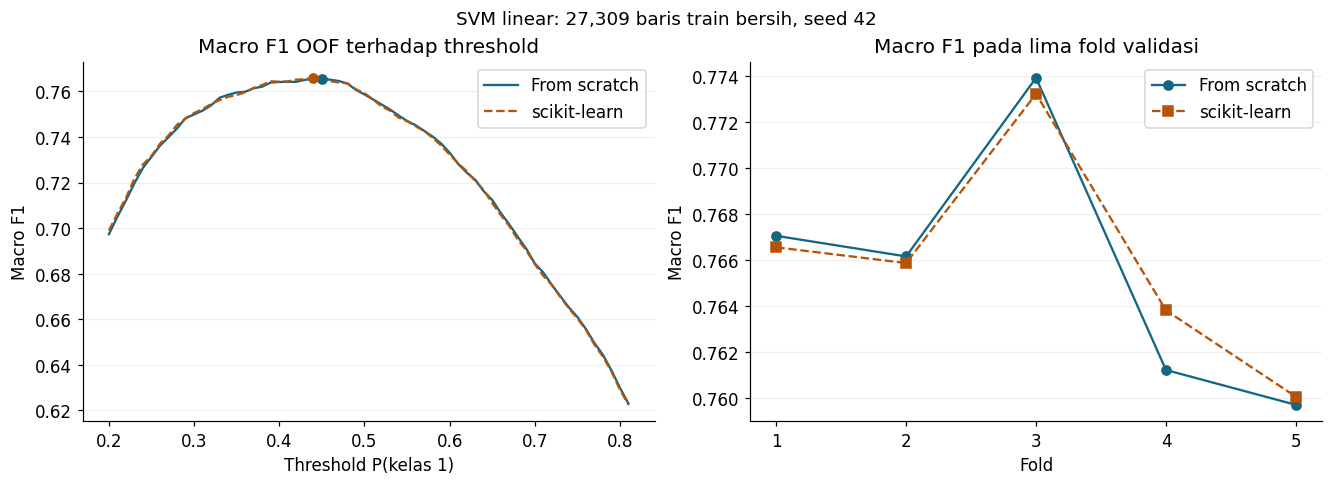

In [6]:
thresholds = np.round(np.arange(0.20, 0.81, 0.01), 2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), layout='constrained')
for name, proba, result, color, style in [
    ('From scratch', oof_scratch, res_scratch, '#126782', '-'),
    ('scikit-learn', oof_sklearn, res_sklearn, '#b45309', '--'),
]:
    axes[0].plot(thresholds, [macro_f1(y, (proba >= t).astype(int)) for t in thresholds],
                 label=name, color=color, linestyle=style)
    axes[0].scatter(result['threshold'], result['oof_macro_f1'], color=color, zorder=3)
axes[0].set(title='Macro F1 OOF terhadap threshold', xlabel='Threshold P(kelas 1)',
            ylabel='Macro F1')
axes[0].legend()
axes[1].plot(per_fold['fold'], per_fold['from_scratch'], 'o-',
             color='#126782', label='From scratch')
axes[1].plot(per_fold['fold'], per_fold['sklearn'], 's--',
             color='#b45309', label='scikit-learn')
axes[1].set(title='Macro F1 pada lima fold validasi', xlabel='Fold', ylabel='Macro F1',
            xticks=range(1, N_FOLDS + 1))
axes[1].legend()
for ax in axes:
    ax.grid(axis='y', alpha=0.2)
fig.suptitle(f'SVM linear: {len(y):,} baris train bersih, seed {SEED}', fontsize=12)
FIG_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(FIG_PATH, dpi=150)
plt.show()

## Training akhir, save/load, dan prediksi test lokal

Model from scratch di-fit ulang pada seluruh train bersih. Preprocessor, model,
dan threshold OOF disimpan bersama seperti notebook baseline tim.
Prediksi sesudah load harus sama persis. File ini belum dikirim ke Kaggle.

In [7]:
prep_final = SVMPreprocessor()
X_train = prep_final.fit_transform(train)
X_test = prep_final.transform(test_raw)
assert TARGET not in X_train.columns and 'id' not in X_train.columns
assert X_train.columns.equals(X_test.columns)
assert np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_test.to_numpy()).all()

started = time.perf_counter()
with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as final_warnings:
    warnings.simplefilter('always', RuntimeWarning)
    model_final = SVM(**SVM_PARAMS).fit(X_train, y)
final_seconds = time.perf_counter() - started
threshold = res_scratch['threshold']
save_model({'preprocessor': prep_final, 'model': model_final, 'threshold': threshold}, MODEL_PATH)
bundle = load_model(MODEL_PATH)
expected_proba = model_final.predict_proba(X_test)
reloaded_proba = bundle['model'].predict_proba(bundle['preprocessor'].transform(test_raw))
assert np.array_equal(expected_proba, reloaded_proba)
assert np.array_equal(model_final.predict(X_test, threshold=threshold),
                      (expected_proba >= threshold).astype(int))
print(f'Training akhir: {final_seconds:.1f} detik | iterasi: {model_final.n_iter_}'
      f' | konvergen: {model_final.converged_} | peringatan: {len(final_warnings)}')
for message in sorted({str(w.message) for w in final_warnings}):
    print(message)

submission = pd.DataFrame({'id': test_raw['id'],
                           TARGET: (reloaded_proba >= bundle['threshold']).astype(int)})
assert submission.shape == sample.shape and submission.columns.equals(sample.columns)
assert submission['id'].equals(sample['id']) and submission[TARGET].isin([0, 1]).all()
SUB_PATH.parent.mkdir(parents=True, exist_ok=True)
submission.to_csv(SUB_PATH, index=False)
saved_submission = pd.read_csv(SUB_PATH, dtype={'id': str})
pd.testing.assert_frame_equal(submission, saved_submission)
print('Model:', MODEL_PATH.relative_to(ROOT))
print('Submission lokal:', SUB_PATH.relative_to(ROOT))
display(submission[TARGET].value_counts().sort_index().rename('jumlah').to_frame())
display(submission.head())

Training akhir: 32.2 detik | iterasi: 55 | konvergen: True | peringatan: 0
Model: output\models\svm_baseline_linear.pkl
Submission lokal: output\submissions\submission_svm_baseline_linear.csv


,jumlah
is_canceled,
0,4836
1,2008


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,1
3,25408a48,0
4,621586b6,0


## Catatan hasil dan langkah berikutnya

Kurva threshold kedua implementasi hampir berimpit. Pada konfigurasi ini, skor
from scratch mendekati scikit-learn; hasil tersebut tidak membuktikan kebenaran
implementasi untuk seluruh data atau parameter. F1 kelas batal (0,6787) masih
lebih rendah daripada kelas tidak batal (0,8526).

Baseline linear tertinggal sekitar 0,0635 dari skor Decision Tree pada log tim.
Eksperimen berikutnya dapat menguji C, feature engineering, dan kernel poly/RBF;
semuanya belum diuji pada notebook ini. Threshold dipilih dan dinilai pada OOF
yang sama, sehingga skor ini tetap hasil pengembangan, bukan test independen.

Model akhir konvergen dalam 55 iterasi (32,2 detik), tanpa peringatan optimasi.
Artefak lokal:

- [Model dan preprocessor](../../../output/models/svm_baseline_linear.pkl)
- CSV baseline dapat dibuat ulang dari bagian training akhir.
- [Grafik diagnostik](../../../output/figures/svm_baseline_linear.png)
- [Log eksperimen](../../../docs/EXPERIMENTS.md)

Environment run tercatat pada output setup. Pada scikit-learn 1.9.0,
`SVC(probability=True)` masih berjalan tetapi memberi FutureWarning; migrasikan
pembanding ke `CalibratedClassifierCV` sebelum memakai versi 1.11.
Tidak ada pengiriman Kaggle dari notebook ini.
